# Predicting the Human Development Index from Development Indicators
**CS 363M — Machine Learning Final Project**

## 1. Introduction

**Problem.** The Human Development Index (HDI), published by the UNDP, summarizes a country's development as a number between 0 and 1. We predict a country's HDI in a given year from World Bank development indicators. This is a **supervised regression** problem.

**Not using the HDI formula's inputs.** HDI is *calculated* from four inputs:
1. life expectancy at birth
2. expected years of schooling
3. mean years of schooling
4. GNI per capita

If we used these, the model would just be re-learning the formula. We therefore **remove every feature that is one of these inputs or a close stand-in for one** (Section 2.3) and only use indicators outside the formula: demographics, infrastructure, economic structure and environment.

**Data.**
| Source | Content | Role |
|---|---|---|
| UNDP Human Development Report 2025: composite indices time series | HDI for 193 countries, 1990–2023 | target |
| World Bank World Development Indicators, via `download_worldbank.py` | development indicators per country-year | features |

Each row is one **country-year**.

**Models.** Linear regression, polynomial regression, K-nearest-neighbors regression, decision tree regression, support vector regression (SVM), and a neural network (multi-layer perceptron).

**Evaluation.** Rows from the same country in different years are very similar, so we split **by country**:
* 20% of countries are held out as a final test set, and
* every model is tuned with **5-fold cross-validation grouped by country**.

Every score therefore measures performance on countries the model has never seen. The main metric is **RMSE**; MAE and R² are also reported.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, RandomizedSearchCV, cross_validate
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, plot_tree

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="A worker stopped")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

## 2. Data Loading & Cleaning

### 2.1 Load the raw files

In [2]:
DATA_DIR = Path("data/raw")
hdi_raw = pd.read_csv(DATA_DIR / "hdi" / "HDR25_Composite_indices_complete_time_series.csv", encoding="latin-1")
wdi_raw = pd.read_csv(DATA_DIR / "worldbank" / "wdi_wide.csv")
countries = pd.read_csv(DATA_DIR / "worldbank" / "countries.csv")

print(f"HDI file:        {hdi_raw.shape[0]:>5} rows x {hdi_raw.shape[1]:>4} columns  (wide: one row per country, one column per year)")
print(f"World Bank file: {wdi_raw.shape[0]:>5} rows x {wdi_raw.shape[1]:>4} columns  (one row per country-year, incl. regional aggregates)")
hdi_raw.iloc[:5, :9]

HDI file:          206 rows x 1112 columns  (wide: one row per country, one column per year)
World Bank file:  9135 rows x   35 columns  (one row per country-year, incl. regional aggregates)


,iso3,country,hdicode,region,hdi_rank_2023,hdi_1990,hdi_1991,hdi_1992,hdi_1993
0,AFG,Afghanistan,Low,SA,181.0,0.285,0.291,0.301,0.311
1,ALB,Albania,Very High,ECA,71.0,0.654,0.638,0.622,0.624
2,DZA,Algeria,High,AS,96.0,0.595,0.596,0.601,0.603
3,AND,Andorra,Very High,NaN,32.0,NaN,NaN,NaN,NaN
4,AGO,Angola,Medium,SSA,148.0,NaN,NaN,NaN,NaN


### 2.2 Clean the HDI data
* The UNDP file contains HDI **and** its component columns: life expectancy (`le_`), expected and mean years of schooling (`eys_`, `mys_`), and GNI per capita (`gnipc_`). We keep **only the `hdi_<year>` columns**, so none of the components can reach the model.
* Drop the 11 aggregate rows (development groups, UNDP regions, World), whose codes start with `ZZ`.
* Reshape from wide to long format: one row per country-year.
* Drop country-years with no HDI value.

In [3]:
hdi_year_cols = [c for c in hdi_raw.columns if c.startswith("hdi_") and c[4:].isdigit()]
component_cols = [c for c in hdi_raw.columns if c.split("_")[0] in ("le", "eys", "mys", "gnipc")]
print(f"Keeping {len(hdi_year_cols)} HDI columns; ignoring {len(component_cols)} HDI-component columns "
      f"(e.g. {component_cols[:2] + component_cols[-2:]})")

is_aggregate = hdi_raw["iso3"].str.startswith("ZZ")
print("Aggregate rows dropped:", hdi_raw.loc[is_aggregate, "country"].tolist(), "\n")

hdi = (hdi_raw.loc[~is_aggregate, ["iso3", "country"] + hdi_year_cols]
       .melt(id_vars=["iso3", "country"], var_name="year", value_name="hdi"))
hdi["year"] = hdi["year"].str[4:].astype(int)

n_before = len(hdi)
no_hdi = hdi.groupby("country")["hdi"].count().loc[lambda s: s == 0].index.tolist()
hdi = hdi.dropna(subset=["hdi"])
print(f"{n_before} country-year slots -> {len(hdi)} with an HDI value "
      f"({hdi.iso3.nunique()} countries, years {hdi.year.min()}-{hdi.year.max()})")
print("Countries with no HDI at all (dropped):", no_hdi)

Keeping 34 HDI columns; ignoring 340 HDI-component columns (e.g. ['le_1990', 'le_1991', 'mys_m_2022', 'mys_m_2023'])
Aggregate rows dropped: ['Very high human development', 'High human development', 'Medium human development', 'Low human development', 'Arab States', 'East Asia and the Pacific', 'Europe and Central Asia', 'Latin America and the Caribbean', 'South Asia', 'Sub-Saharan Africa', 'World'] 

6630 country-year slots -> 5940 with an HDI value (193 countries, years 1990-2023)
Countries with no HDI at all (dropped): ["Korea (Democratic People's Rep. of)", 'Monaco']


### 2.3 Clean the World Bank data and remove HDI inputs
The World Bank download includes some indicators that are HDI inputs or close stand-ins for them. We **drop them before anything else**, so they are never explored or modeled:

| HDI input | World Bank column(s) removed | Why |
|---|---|---|
| Life expectancy at birth | `life_expectancy` | the same measure |
| | `infant_mortality`, `under5_mortality` | child deaths directly determine life expectancy |
| Expected / mean years of schooling | `secondary_enrollment` | stand-in for years of schooling |
| GNI per capita | `gni_pc_ppp` | the same measure |
| | `gdp_pc_ppp` | nearly identical to GNI per capita |

We also leave out the World Bank *income group*, because it is defined by GNI per capita.

Other steps:
* Drop the ~50 aggregate "countries" in the World Bank file (e.g. *Sub-Saharan Africa*, *High income*).
* Add each country's World Bank **region** as a categorical feature.
* Join onto the HDI rows by `(iso3, year)`.

In [4]:
HDI_INPUTS = ["life_expectancy", "infant_mortality", "under5_mortality",
              "secondary_enrollment", "gni_pc_ppp", "gdp_pc_ppp"]

REGION_SHORT = {
    "Europe & Central Asia": "Europe & C. Asia",
    "Sub-Saharan Africa": "Sub-Saharan Africa",
    "Latin America & Caribbean": "Latin America & Carib.",
    "East Asia & Pacific": "East Asia & Pacific",
    "Middle East, North Africa, Afghanistan & Pakistan": "MENA, Afg. & Pak.",
    "South Asia": "South Asia",
    "North America": "North America",
}
wb_meta = countries.loc[countries.region != "Aggregates", ["iso3", "region"]].copy()
wb_meta["region"] = wb_meta["region"].map(REGION_SHORT)

wdi = wdi_raw[wdi_raw.iso3.isin(wb_meta.iso3)].drop(columns=["country"] + HDI_INPUTS)
print("World Bank aggregate rows dropped:", len(wdi_raw) - len(wdi))
print("HDI-input columns dropped:", HDI_INPUTS)
assert not wdi.duplicated(["iso3", "year"]).any(), "duplicate country-years"

FEATURES_RAW = [c for c in wdi.columns if c not in ("iso3", "year")]
assert not set(FEATURES_RAW) & set(HDI_INPUTS)

df = (hdi.merge(wdi, on=["iso3", "year"], how="left", validate="one_to_one")
         .merge(wb_meta, on="iso3", how="left", validate="many_to_one")
         .sort_values(["iso3", "year"]).reset_index(drop=True))

print("\nMerged shape:", df.shape)
print("HDI rows with no World Bank data at all:", int(df[FEATURES_RAW].isna().all(axis=1).sum()))
print("Countries without a region:", df.loc[df.region.isna(), "country"].unique().tolist())
print(f"\n{len(FEATURES_RAW)} indicators used as features:\n", FEATURES_RAW)

World Bank aggregate rows dropped: 1540
HDI-input columns dropped: ['life_expectancy', 'infant_mortality', 'under5_mortality', 'secondary_enrollment', 'gni_pc_ppp', 'gdp_pc_ppp']

Merged shape: (5940, 31)
HDI rows with no World Bank data at all: 0
Countries without a region: []

26 indicators used as features:
 ['adolescent_fertility', 'agri_employment_pct', 'agriculture_gdp_pct', 'basic_sanitation_pct', 'basic_water_pct', 'birth_rate', 'clean_cooking_access_pct', 'co2_per_capita', 'elec_kwh_per_capita', 'electricity_access_pct', 'female_lfp_pct', 'fertility_rate', 'forest_area_pct', 'health_exp_gdp_pct', 'industry_gdp_pct', 'inflation_pct', 'internet_users_pct', 'mobile_subs_per100', 'pop_0_14_pct', 'pop_65up_pct', 'pop_density', 'pop_growth_pct', 'population', 'services_gdp_pct', 'trade_gdp_pct', 'urban_pop_pct']


### 2.4 Sanity checks

In [5]:
assert df.hdi.between(0, 1).all()
share_cols = ["urban_pop_pct", "electricity_access_pct", "clean_cooking_access_pct", "basic_water_pct",
              "basic_sanitation_pct", "internet_users_pct", "agriculture_gdp_pct", "industry_gdp_pct",
              "services_gdp_pct", "agri_employment_pct", "female_lfp_pct", "health_exp_gdp_pct",
              "forest_area_pct", "pop_0_14_pct", "pop_65up_pct"]
out_of_range = {c: int((~df[c].dropna().between(0, 100)).sum()) for c in share_cols}
print("Percentage columns with values outside [0, 100]:", {k: v for k, v in out_of_range.items() if v} or "none")
print("Negative values in non-negative columns:",
      {c: int((df[c] < 0).sum()) for c in ["population", "pop_density", "co2_per_capita", "elec_kwh_per_capita",
                                           "trade_gdp_pct", "mobile_subs_per100"] if (df[c] < 0).any()} or "none")

df["hdi_change"] = df.groupby("iso3")["hdi"].diff()
print("\nLargest year-over-year HDI changes:")
display(df.loc[df.hdi_change.abs().nlargest(6).index, ["country", "year", "hdi", "hdi_change"]])
df = df.drop(columns="hdi_change")

Percentage columns with values outside [0, 100]: none
Negative values in non-negative columns: none

Largest year-over-year HDI changes:


,country,year,hdi,hdi_change
889,Central African Republic,2019,0.279,-0.112
890,Central African Republic,2020,0.386,0.107
2356,Haiti,2011,0.536,0.084
2355,Haiti,2010,0.452,-0.082
4905,South Sudan,2018,0.371,0.079
892,Central African Republic,2023,0.414,0.075


No values fall outside their valid ranges. The largest HDI jumps line up with real events, such as conflict in the Central African Republic and South Sudan and the 2010 earthquake in Haiti, not data-entry errors, so we keep them.

## 3. Data Exploration

### 3.1 Summary statistics

In [6]:
df[["hdi"] + FEATURES_RAW].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
hdi,5940.0,0.68,1.600000e-01,0.22,0.56,0.71,0.81,9.700000e-01
adolescent_fertility,5940.0,56.36,4.554000e+01,0.54,17.72,45.20,84.52,2.122500e+02
agri_employment_pct,5495.0,27.14,2.266000e+01,0.08,6.69,20.67,43.29,9.242000e+01
agriculture_gdp_pct,5551.0,12.09,1.131000e+01,0.00,2.98,8.34,18.76,7.904000e+01
basic_sanitation_pct,4378.0,73.08,2.951000e+01,2.97,48.90,86.95,97.64,1.000000e+02
basic_water_pct,4383.0,85.72,1.786000e+01,18.76,77.06,93.88,99.02,1.000000e+02
birth_rate,5940.0,22.69,1.140000e+01,4.40,12.31,20.73,31.41,5.509000e+01
clean_cooking_access_pct,4416.0,64.76,3.777000e+01,0.00,29.00,86.00,98.00,1.000000e+02
co2_per_capita,5784.0,5.06,8.700000e+00,0.00,0.61,2.29,6.72,2.028700e+02
elec_kwh_per_capita,4706.0,3843.92,5.377280e+03,0.00,557.56,2010.95,5158.32,5.508517e+04


### 3.2 The target: HDI

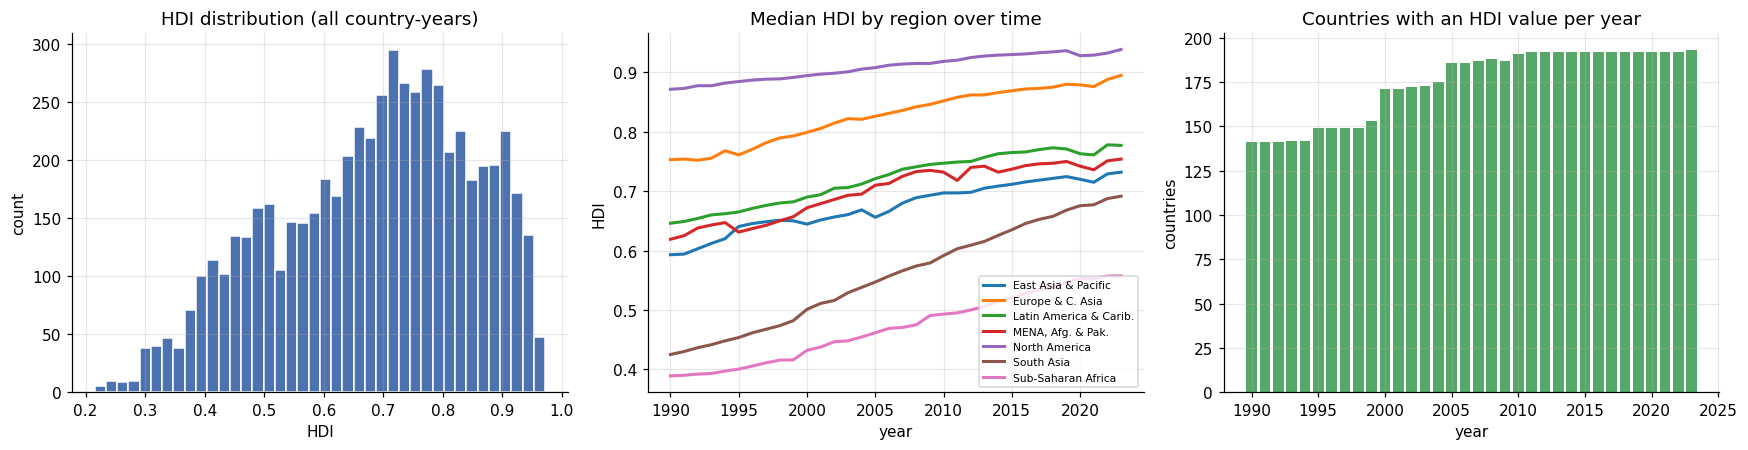

Share of HDI variance that is between countries: 91%


In [7]:
regions = sorted(df.region.unique())
REGION_COLORS = dict(zip(regions, plt.cm.tab10.colors))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(df.hdi, bins=40, color="#4C72B0", edgecolor="white")
axes[0].set(title="HDI distribution (all country-years)", xlabel="HDI", ylabel="count")
for r in regions:
    s = df[df.region == r].groupby("year").hdi.median()
    axes[1].plot(s.index, s.values, label=r, color=REGION_COLORS[r], lw=2)
axes[1].set(title="Median HDI by region over time", xlabel="year", ylabel="HDI")
axes[1].legend(fontsize=7)
counts = df.groupby("year").iso3.nunique()
axes[2].bar(counts.index, counts.values, color="#55A868")
axes[2].set(title="Countries with an HDI value per year", xlabel="year", ylabel="countries")
plt.tight_layout(); plt.show()

country_mean = df.groupby("iso3").hdi.transform("mean")
print(f"Share of HDI variance that is between countries: {country_mean.var() / df.hdi.var():.0%}")

* HDI is **left-skewed**. Most country-years fall between 0.6 and 0.9, with a long tail down to ~0.2.
* Every region rises steadily over time. North America is highest and Sub-Saharan Africa lowest, and several regions **dip in 2020–2021** (COVID-19).
* The panel is **unbalanced**: about 140 countries have an HDI in 1990, rising to 193 by 2023.
* About **90% of HDI's variance is between countries**. A random row split would let a model "recognize" countries it has already seen, which is why we split by country.

### 3.3 Missing values

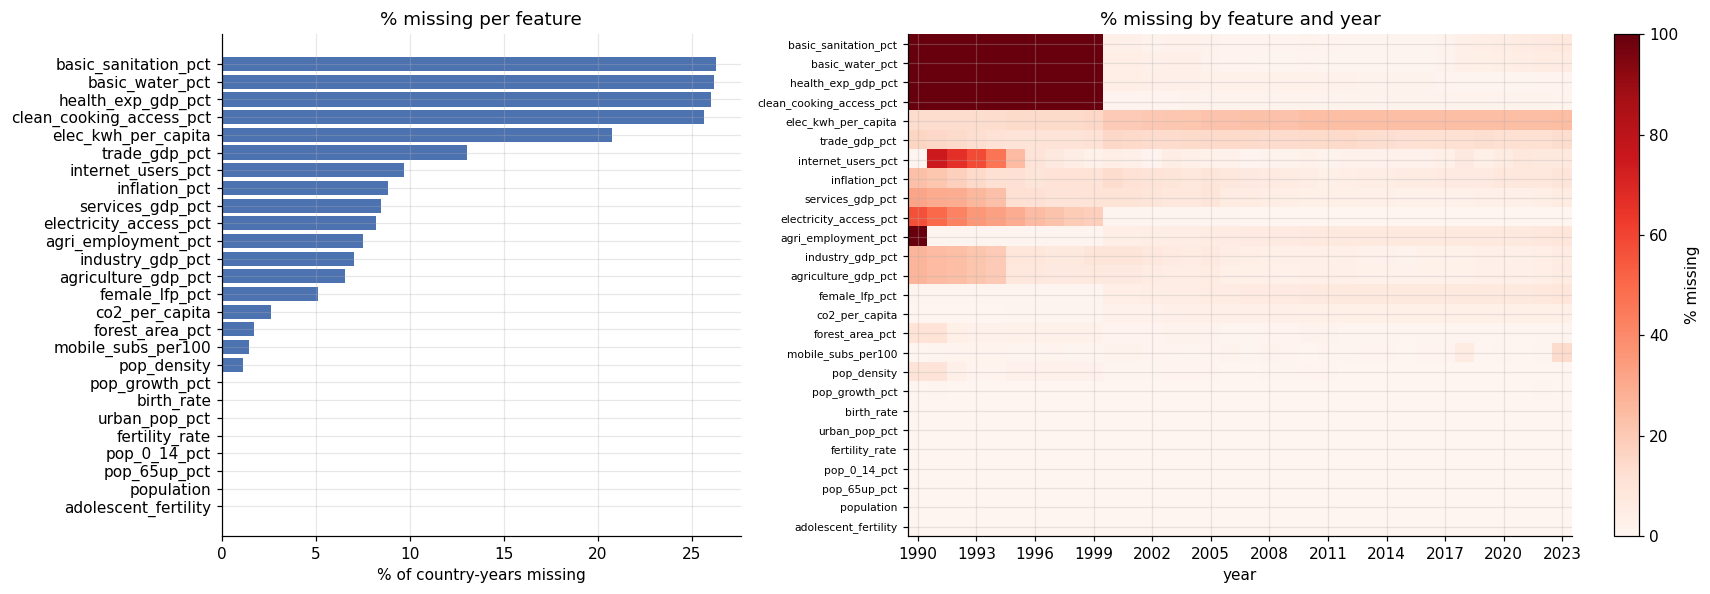

In [8]:
miss = df[FEATURES_RAW].isna().mean().sort_values() * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].barh(miss.index, miss.values, color="#4C72B0")
axes[0].set(title="% missing per feature", xlabel="% of country-years missing")
by_year = df.groupby("year")[miss.index[::-1]].apply(lambda g: g.isna().mean()).T * 100
im = axes[1].imshow(by_year.values, aspect="auto", cmap="Reds", vmin=0, vmax=100)
axes[1].set_yticks(range(len(by_year)), by_year.index, fontsize=7)
axes[1].set_xticks(range(0, by_year.shape[1], 3), by_year.columns[::3])
axes[1].set(title="% missing by feature and year", xlabel="year")
fig.colorbar(im, ax=axes[1], label="% missing")
plt.tight_layout(); plt.show()

Missing data follows a clear pattern:
* Water, sanitation, clean cooking and health spending only start around **2000**.
* Electricity use per capita is missing for whole countries.
* Recent years are missing for some indicators the World Bank hasn't published yet.

This suggests filling gaps **within each country over time** (Section 4.1) rather than with a global average.

### 3.4 Relationships with HDI

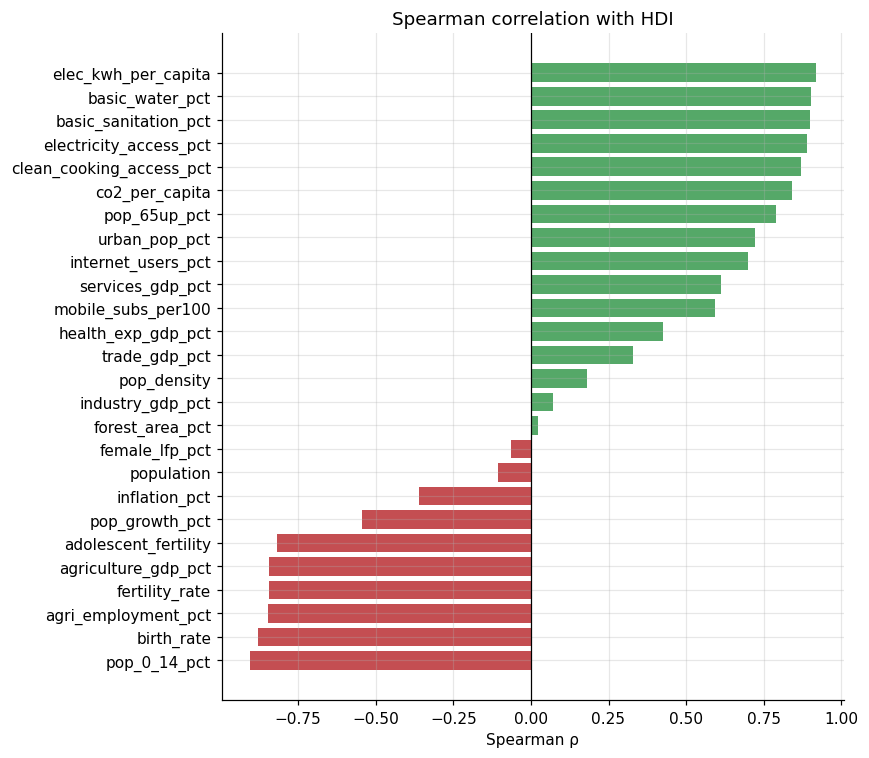

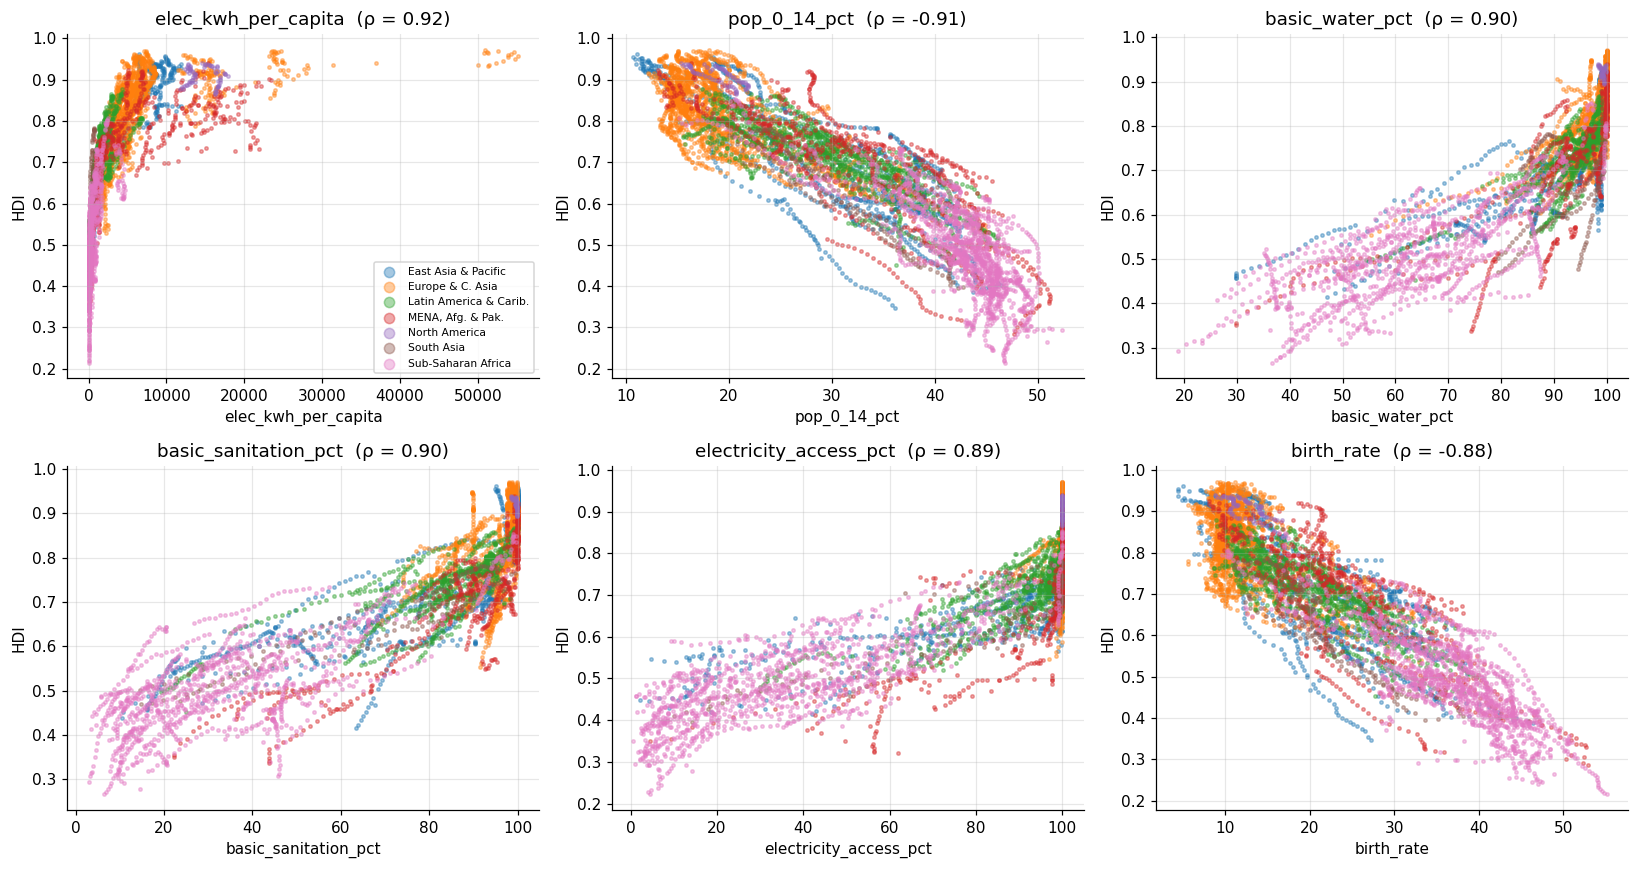

In [9]:
corr = df[FEATURES_RAW].corrwith(df.hdi, method="spearman").sort_values()
plt.figure(figsize=(8, 7))
plt.barh(corr.index, corr.values, color=["#55A868" if v > 0 else "#C44E52" for v in corr.values])
plt.axvline(0, color="black", lw=0.8)
plt.title("Spearman correlation with HDI"); plt.xlabel("Spearman ρ"); plt.tight_layout(); plt.show()

top6 = corr.abs().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, top6):
    for r in regions:
        m = df.region == r
        ax.scatter(df.loc[m, col], df.loc[m, "hdi"], s=5, alpha=0.4, color=REGION_COLORS[r], label=r)
    ax.set(xlabel=col, ylabel="HDI", title=f"{col}  (ρ = {corr[col]:.2f})")
axes[0, 0].legend(fontsize=7, markerscale=3)
plt.tight_layout(); plt.show()

* **Strong positive** correlations: electricity use per capita and access to water, sanitation, electricity and clean cooking.
* **Strong negative** correlations: the share of population under 15, birth and fertility rates, and the size of the agricultural sector.
* **Weak** correlations: forest area, female labor force participation, industry share of GDP, population.
* Many relationships are **non-linear**. For example, HDI levels off as access approaches 100%. This suggests non-linear models (polynomial, KNN, trees, SVM, neural networks) may beat plain linear regression.

### 3.5 Correlation between features

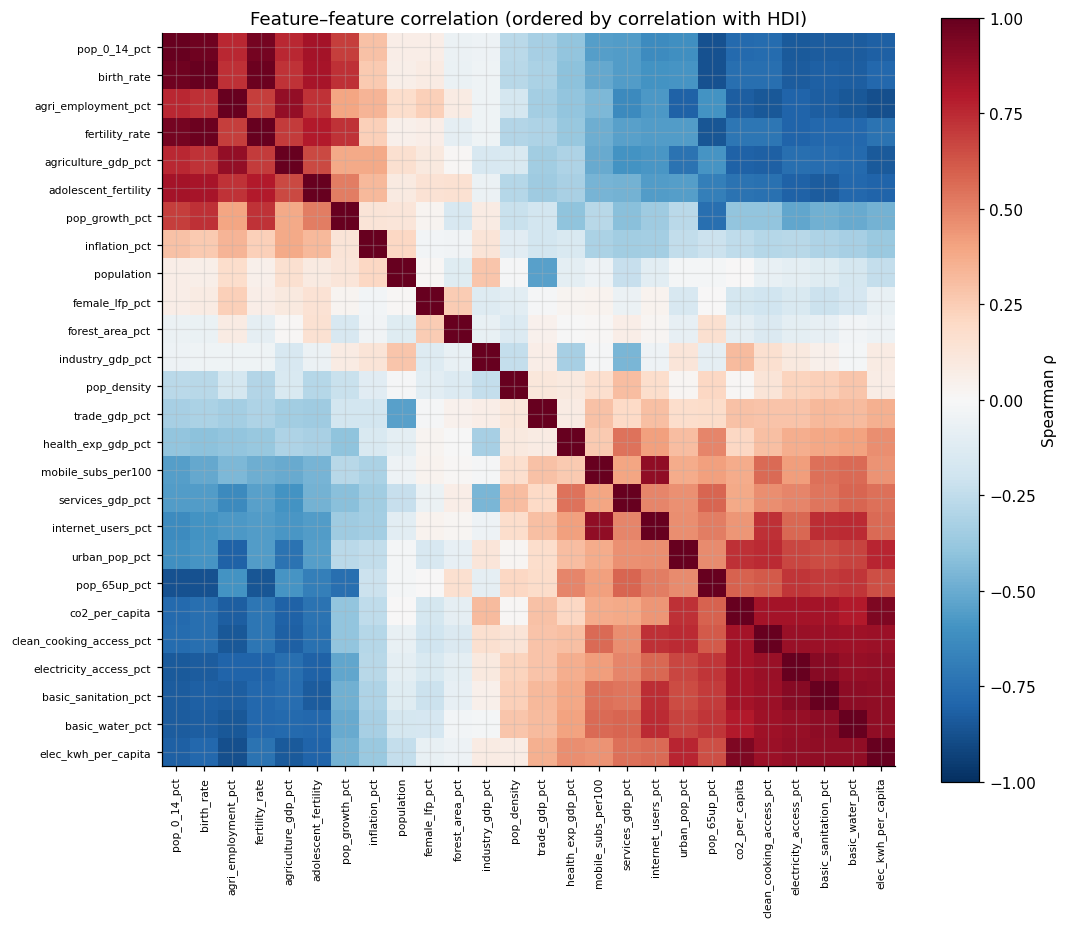

Feature pairs with |ρ| > 0.9:
 birth_rate              fertility_rate          0.982
pop_0_14_pct            birth_rate              0.976
                        fertility_rate          0.959
co2_per_capita          elec_kwh_per_capita     0.930
electricity_access_pct  basic_sanitation_pct    0.908


In [10]:
order = corr.sort_values().index
cm = df[order].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=7)
ax.set_yticks(range(len(order)), order, fontsize=7)
fig.colorbar(im, ax=ax, label="Spearman ρ")
ax.set_title("Feature–feature correlation (ordered by correlation with HDI)")
plt.tight_layout(); plt.show()

pairs = (cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1)).stack()
           .loc[lambda s: s.abs() > 0.9].sort_values(ascending=False))
print("Feature pairs with |ρ| > 0.9:\n", pairs.round(3).to_string())

The demographic features (fertility, birth rate, share under 15) are almost duplicates of each other, and the infrastructure features form another tightly correlated block. This makes individual linear-regression coefficients unreliable. It also motivates combining the access indicators into one feature (Section 4.2).

### 3.6 Skewed features

Skewness: {'population': 8.1, 'pop_density': 8.2, 'co2_per_capita': 6.9, 'elec_kwh_per_capita': 3.8, 'trade_gdp_pct': 2.6, 'inflation_pct': 54.8}


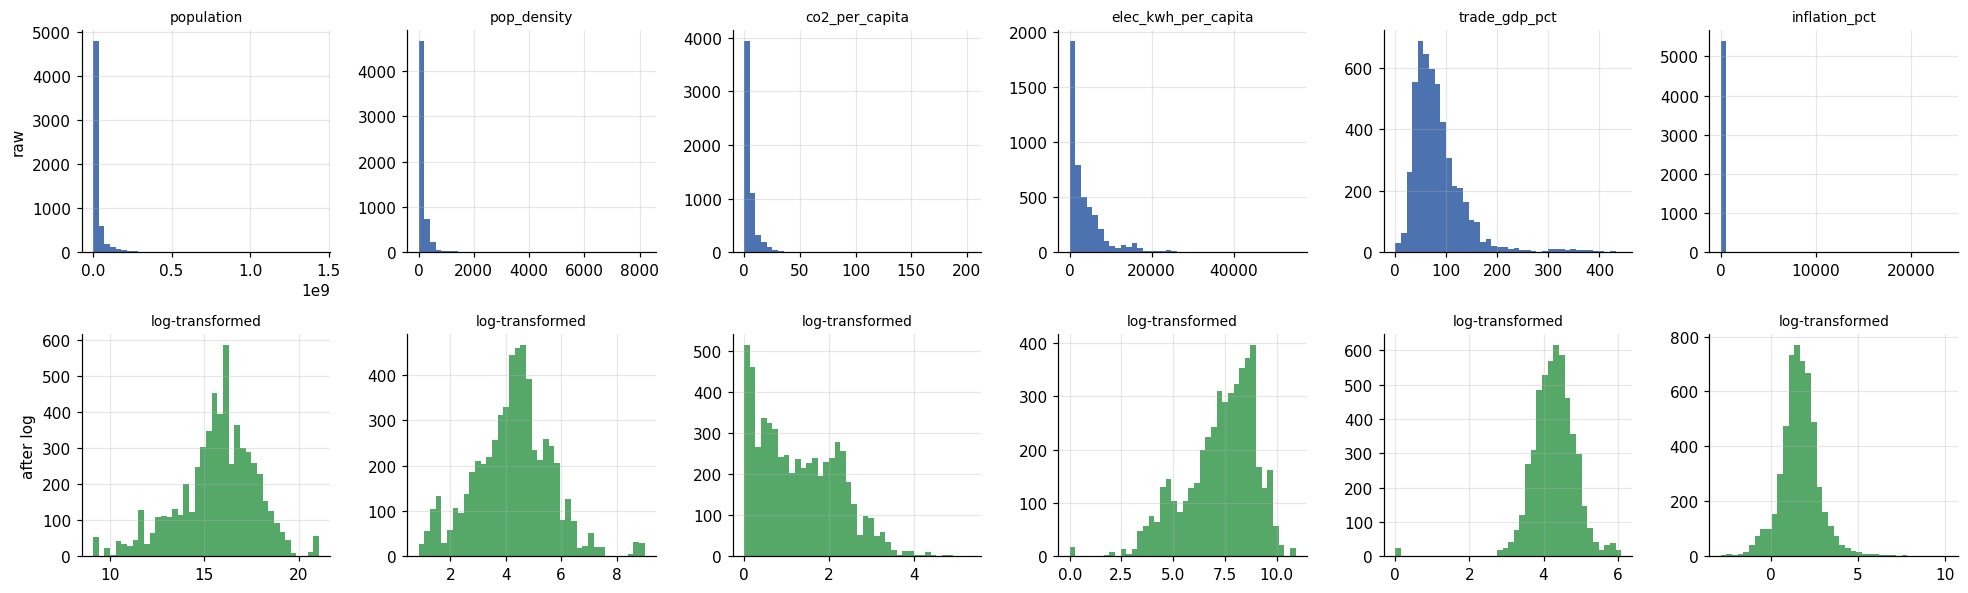

In [11]:
skew_cols = ["population", "pop_density", "co2_per_capita", "elec_kwh_per_capita", "trade_gdp_pct", "inflation_pct"]
print("Skewness:", df[skew_cols].skew().round(1).to_dict())
fig, axes = plt.subplots(2, len(skew_cols), figsize=(18, 5.5))
for i, c in enumerate(skew_cols):
    x = df[c].dropna()
    axes[0, i].hist(x, bins=40, color="#4C72B0"); axes[0, i].set_title(c, fontsize=9)
    tx = np.sign(x) * np.log1p(np.abs(x)) if c == "inflation_pct" else np.log1p(x)
    axes[1, i].hist(tx, bins=40, color="#55A868"); axes[1, i].set_title("log-transformed", fontsize=9)
axes[0, 0].set_ylabel("raw"); axes[1, 0].set_ylabel("after log")
plt.tight_layout(); plt.show()

Population, density, CO2, electricity use, trade and especially inflation, which has hyperinflation episodes above 20,000%, are **heavily right-skewed**. A log transform makes them much more symmetric. That matters for the distance- and gradient-based models (KNN, SVM, neural network) and for linear and polynomial regression.

## 4. Feature Engineering

### 4.1 Filling missing values within each country
Each feature is filled from **the same country's other years**:
1. linear interpolation between observed years,
2. forward-fill after the last observed year,
3. back-fill before the first.

For the five features with the most missing data, a 0/1 `_was_missing` flag records which values were filled. A value that is still missing (a country with no data at all for that feature) is filled with the training-set median inside the modeling pipeline. Because the split is by country, filling within a country never moves information between training and test countries.

In [12]:
HIGH_MISSING = df[FEATURES_RAW].isna().mean().loc[lambda s: s > 0.15].index.tolist()
print("Features with >15% missing (get a _was_missing flag):", HIGH_MISSING)

def impute_within_country(data, cols):
    out = data.sort_values(["iso3", "year"]).copy()
    for c in HIGH_MISSING:
        out[f"{c}_was_missing"] = out[c].isna().astype(int)
    out[cols] = out.groupby("iso3")[cols].transform(lambda s: s.interpolate(limit_area="inside").ffill().bfill())
    return out

df_imp = impute_within_country(df, FEATURES_RAW)
before, after = df[FEATURES_RAW].isna().mean() * 100, df_imp[FEATURES_RAW].isna().mean() * 100
print(f"\nOverall missing: {before.mean():.1f}% -> {after.mean():.1f}%")
pd.DataFrame({"% missing before": before, "% missing after": after}).round(1).sort_values("% missing before", ascending=False).head(8)

Features with >15% missing (get a _was_missing flag): ['basic_sanitation_pct', 'basic_water_pct', 'clean_cooking_access_pct', 'elec_kwh_per_capita', 'health_exp_gdp_pct']

Overall missing: 7.9% -> 1.9%


,% missing before,% missing after
basic_sanitation_pct,26.3,0.6
basic_water_pct,26.2,0.6
health_exp_gdp_pct,26.0,0.6
clean_cooking_access_pct,25.7,1.3
elec_kwh_per_capita,20.8,20.7
trade_gdp_pct,13.0,7.3
internet_users_pct,9.7,0.0
inflation_pct,8.8,2.3


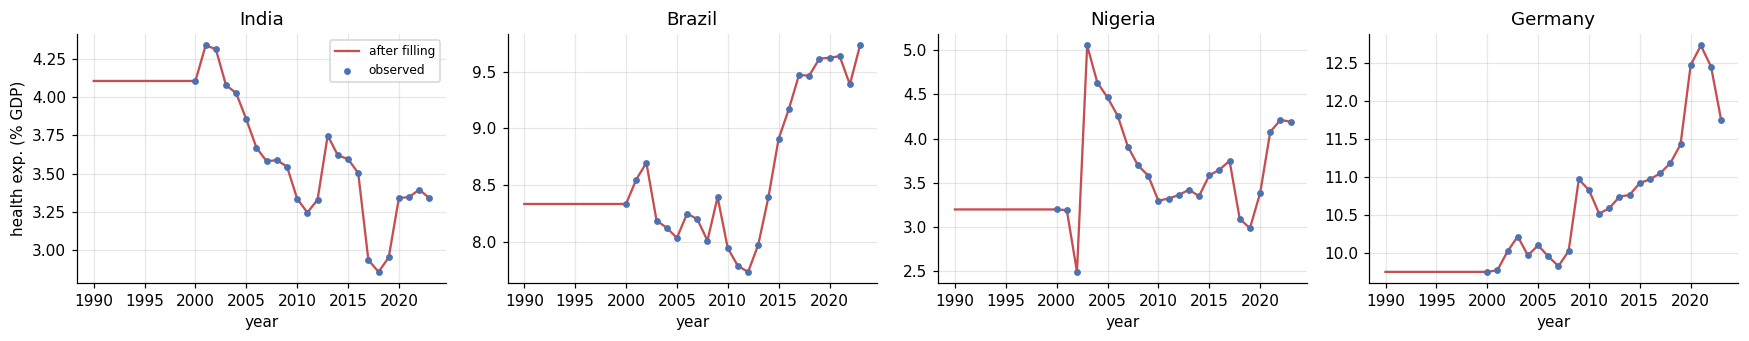

In [13]:
examples = ["IND", "BRA", "NGA", "DEU"]
fig, axes = plt.subplots(1, len(examples), figsize=(16, 3.2))
for ax, iso in zip(axes, examples):
    raw = df[df.iso3 == iso]; imp = df_imp[df_imp.iso3 == iso]
    ax.plot(imp.year, imp.health_exp_gdp_pct, color="#C44E52", lw=1.5, label="after filling")
    ax.scatter(raw.year, raw.health_exp_gdp_pct, s=12, color="#4C72B0", zorder=3, label="observed")
    ax.set_title(raw.country.iloc[0]); ax.set_xlabel("year")
axes[0].set_ylabel("health exp. (% GDP)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4.2 Transformations and new features
| Feature | Construction | Reason |
|---|---|---|
| `log_population`, `log_pop_density`, `log_co2_per_capita`, `log_elec_kwh_per_capita`, `log_trade_gdp_pct` | `log(1 + x)` | remove heavy right skew (3.6) |
| `slog_inflation` | `sign(x)·log(1+|x|)` | handles hyperinflation **and** deflation (negative values) |
| `dependency_ratio` | (under-15 + over-65) / working-age share | combines the two age-structure features into one standard measure |
| `basic_services_index` | mean of electricity, clean cooking, water, sanitation access | one less-noisy infrastructure score from a highly correlated block (3.5) |
| `years_since_1990` | `year − 1990` | captures the overall upward trend (3.2) |
| `*_was_missing` | 0/1 flags | lets models tell real values from filled ones |
| `region` | one-hot encoded | regional effects the indicators don't capture |

34 numeric features + region (7 categories after one-hot)


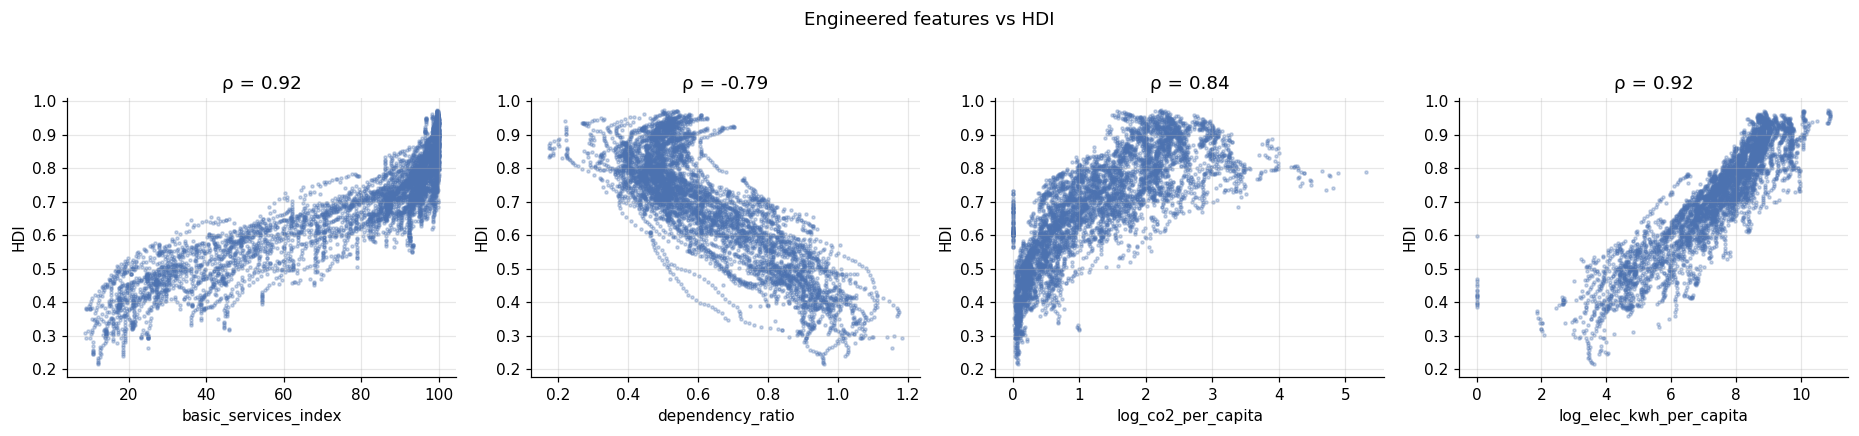

In [14]:
LOG_COLS = ["population", "pop_density", "co2_per_capita", "elec_kwh_per_capita", "trade_gdp_pct"]

def add_features(data):
    out = data.copy()
    for c in LOG_COLS:
        out[f"log_{c}"] = np.log1p(out[c])
    out["slog_inflation"] = np.sign(out.inflation_pct) * np.log1p(out.inflation_pct.abs())
    young, old = out.pop_0_14_pct, out.pop_65up_pct
    out["dependency_ratio"] = (young + old) / (100 - young - old)
    out["basic_services_index"] = out[["electricity_access_pct", "clean_cooking_access_pct",
                                       "basic_water_pct", "basic_sanitation_pct"]].mean(axis=1)
    out["years_since_1990"] = out.year - 1990
    return out

data = add_features(df_imp)

REPLACED = set(LOG_COLS) | {"inflation_pct"}
NUM_FEATURES = ([c for c in FEATURES_RAW if c not in REPLACED]
                + [f"log_{c}" for c in LOG_COLS]
                + ["slog_inflation", "dependency_ratio", "basic_services_index", "years_since_1990"]
                + [f"{c}_was_missing" for c in HIGH_MISSING])
CAT_FEATURES = ["region"]
assert not set(NUM_FEATURES) & set(HDI_INPUTS)
print(f"{len(NUM_FEATURES)} numeric features + region ({data.region.nunique()} categories after one-hot)")

new_feats = ["basic_services_index", "dependency_ratio", "log_co2_per_capita", "log_elec_kwh_per_capita"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, c in zip(axes, new_feats):
    ax.scatter(data[c], data.hdi, s=4, alpha=0.3, color="#4C72B0")
    ax.set(xlabel=c, ylabel="HDI", title=f"ρ = {data[c].corr(data.hdi, method='spearman'):.2f}")
plt.suptitle("Engineered features vs HDI", y=1.03); plt.tight_layout(); plt.show()

After the log transform, CO2 and electricity use per capita have a roughly linear relationship with HDI. The new `basic_services_index` has a strong, smooth relationship with HDI.

## 5. Modeling

### 5.1 Train/test split by country

Train: 4789 rows, 154 countries
Test:  1151 rows, 39 countries (not used until Section 6)


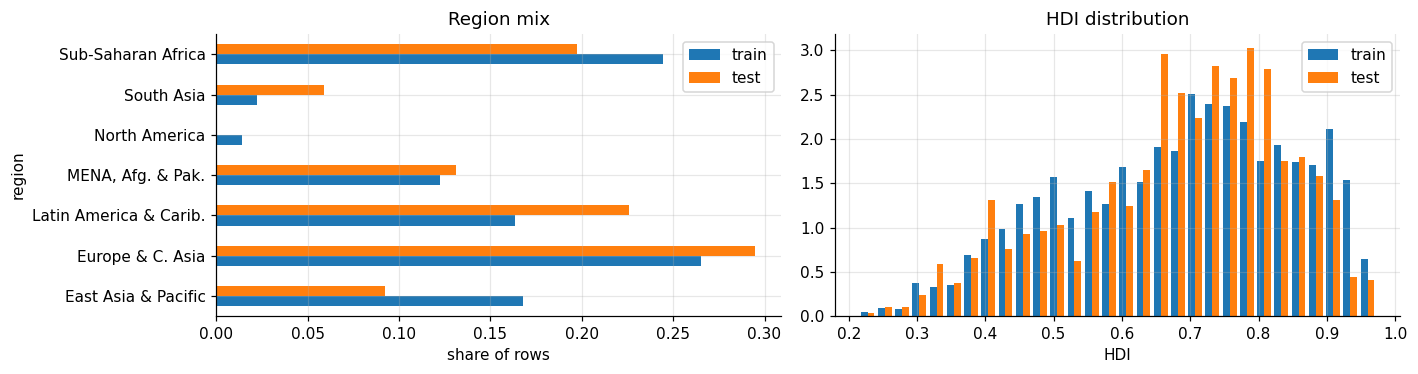

In [15]:
X = data[NUM_FEATURES + CAT_FEATURES]
y = data["hdi"]
groups = data["iso3"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(g_train).isdisjoint(g_test)

print(f"Train: {len(X_train)} rows, {g_train.nunique()} countries")
print(f"Test:  {len(X_test)} rows, {g_test.nunique()} countries (not used until Section 6)")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
pd.DataFrame({"train": X_train.region.value_counts(normalize=True),
              "test": X_test.region.value_counts(normalize=True)}).plot.barh(ax=axes[0])
axes[0].set(title="Region mix", xlabel="share of rows")
axes[1].hist([y_train, y_test], bins=30, density=True, label=["train", "test"])
axes[1].set(title="HDI distribution", xlabel="HDI"); axes[1].legend()
plt.tight_layout(); plt.show()

### 5.2 Preprocessing pipeline and evaluation helpers
Each model is wrapped in a `Pipeline` with these steps:
1. median imputation, for the few values still missing,
2. standardization (z-scores),
3. one-hot encoding of the region.

The pipeline is re-fit inside every cross-validation fold, so the validation countries never influence preprocessing. Each model's hyperparameters are tuned with the same 5-fold **GroupKFold**.

In [16]:
cv = GroupKFold(n_splits=5)
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
results, fitted = {}, {}

def make_preprocessor(num_cols=None, cat_cols=CAT_FEATURES):
    num_cols = NUM_FEATURES if num_cols is None else num_cols
    steps = [("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                               ("scale", StandardScaler())]), num_cols)]
    if cat_cols:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols))
    return ColumnTransformer(steps)

def make_pipe(model, num_cols=None, cat_cols=CAT_FEATURES):
    return Pipeline([("pre", make_preprocessor(num_cols, cat_cols)), ("model", model)])

def _store(name, r, i, estimator):
    results[name] = dict(cv_rmse=-r["mean_test_rmse"][i], cv_rmse_std=r["std_test_rmse"][i],
                         cv_mae=-r["mean_test_mae"][i], cv_r2=r["mean_test_r2"][i],
                         train_rmse=abs(r["mean_train_rmse"][i]))
    fitted[name] = estimator
    s = results[name]
    print(f"{name:<30} CV RMSE = {s['cv_rmse']:.4f} ± {s['cv_rmse_std']:.4f} | MAE = {s['cv_mae']:.4f} "
          f"| R² = {s['cv_r2']:.3f} | train RMSE = {s['train_rmse']:.4f}")

def evaluate(name, pipe):
    # Cross-validate a model that has no hyperparameters, then fit it on all training countries.
    s = cross_validate(pipe, X_train, y_train, groups=g_train, cv=cv, scoring=SCORING,
                       return_train_score=True, n_jobs=-1)
    r = {f"mean_{k}": [v.mean()] for k, v in s.items()} | {f"std_{k}": [v.std()] for k, v in s.items()}
    _store(name, r, 0, pipe.fit(X_train, y_train))

def tune(name, pipe, grid, n_iter=None):
    # Grid search (or randomized search if n_iter is set) with grouped CV; refit the best on all training data.
    kw = dict(scoring=SCORING, refit="rmse", cv=cv, n_jobs=-1, return_train_score=True)
    search = (RandomizedSearchCV(pipe, grid, n_iter=n_iter, random_state=RANDOM_STATE, **kw) if n_iter
              else GridSearchCV(pipe, grid, **kw))
    search.fit(X_train, y_train, groups=g_train)
    print("best params:", {k.split("__")[-1]: v for k, v in search.best_params_.items()})
    _store(name, search.cv_results_, search.best_index_, search.best_estimator_)
    return search

### 5.3 Linear regression
We fit two versions. **Simple linear regression** uses only the single feature most correlated with HDI and serves as a reference point. **Multiple linear regression** uses all features.

In [17]:
best_single = X_train[NUM_FEATURES].corrwith(y_train).abs().idxmax()
print(f"Single most-correlated feature: {best_single}")
evaluate("Simple linear regression", make_pipe(LinearRegression(), num_cols=[best_single], cat_cols=[]))
evaluate("Multiple linear regression", make_pipe(LinearRegression()))

Single most-correlated feature: basic_services_index


Simple linear regression       CV RMSE = 0.0727 ± 0.0059 | MAE = 0.0596 | R² = 0.792 | train RMSE = 0.0721


Multiple linear regression     CV RMSE = 0.0445 ± 0.0051 | MAE = 0.0353 | R² = 0.923 | train RMSE = 0.0349


### 5.4 Polynomial regression
We add squared and interaction terms to capture the curved relationships seen in 3.4. With ~40 features, degree 2 already creates ~900 terms and degree 3 more than 12,000. Plain least squares would overfit badly with that many terms. We therefore tune two settings together:
* `k`: how many features to keep, choosing the k most related to HDI (`SelectKBest`) **inside each training fold**,
* `degree`: the polynomial degree (2 or 3).

best params: {'degree': 3, 'k': 3}
Polynomial regression          CV RMSE = 0.0503 ± 0.0038 | MAE = 0.0400 | R² = 0.904 | train RMSE = 0.0467


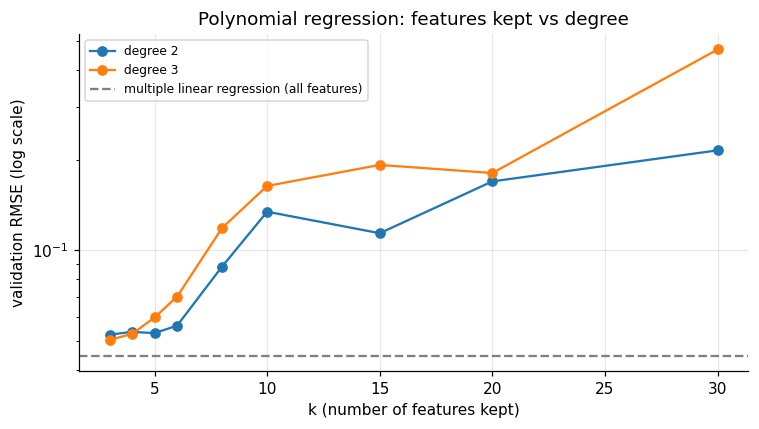

Features kept by the best polynomial model: ['num__birth_rate', 'num__pop_0_14_pct', 'num__basic_services_index']
param_poly__degree       2       3
param_select__k                   
3                   0.0524  0.0503
4                   0.0535  0.0526
5                   0.0530  0.0597
6                   0.0561  0.0701
8                   0.0883  0.1187
10                  0.1345  0.1639
15                  0.1140  0.1926
20                  0.1697  0.1810
30                  0.2154  0.4670


In [18]:
poly_pipe = Pipeline([("pre", make_preprocessor()),
                      ("select", SelectKBest(f_regression)),
                      ("poly", PolynomialFeatures(include_bias=False)),
                      ("model", LinearRegression())])
poly_search = tune("Polynomial regression", poly_pipe,
                   {"select__k": [3, 4, 5, 6, 8, 10, 15, 20, 30], "poly__degree": [2, 3]})

r = pd.DataFrame(poly_search.cv_results_)
fig, ax = plt.subplots(figsize=(7, 4))
for d, g in r.groupby("param_poly__degree"):
    ax.plot(g.param_select__k, -g.mean_test_rmse, "o-", label=f"degree {d}")
ax.axhline(results["Multiple linear regression"]["cv_rmse"], color="gray", ls="--", label="multiple linear regression (all features)")
ax.set_yscale("log"); ax.set(xlabel="k (number of features kept)", ylabel="validation RMSE (log scale)",
                             title="Polynomial regression: features kept vs degree")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("Features kept by the best polynomial model:",
      list(fitted["Polynomial regression"].named_steps["pre"].get_feature_names_out()
           [fitted["Polynomial regression"].named_steps["select"].get_support()]))
print((-r.pivot(index="param_select__k", columns="param_poly__degree", values="mean_test_rmse")).round(4))

**Observations:**
* Without regularization, polynomial regression **overfits quickly** as features or degree are added. With 30 features at degree 3, validation RMSE reaches 0.47, worse than always predicting the average HDI.
* The best polynomial model uses **degree 3 on only 3 features**: `birth_rate`, `pop_0_14_pct` and `basic_services_index`. Its CV RMSE is **0.050**, better than simple linear regression on one feature (0.073).
* It still does **worse than multiple linear regression on all features (0.045)**. The number of polynomial terms grows so fast that the model can only afford a handful of features, and the curvature it captures does not make up for the information it leaves out.

### 5.5 K-nearest-neighbors regression
KNN predicts the average HDI of the *k* most similar training country-years. Because it is based on distance, it relies on the scaling and log transforms from Section 4. We tune *k*, uniform vs distance weighting, and Manhattan (p=1) vs Euclidean (p=2) distance.

best params: {'n_neighbors': 50, 'p': 1, 'weights': 'distance'}
KNN regression                 CV RMSE = 0.0416 ± 0.0027 | MAE = 0.0313 | R² = 0.932 | train RMSE = 0.0000


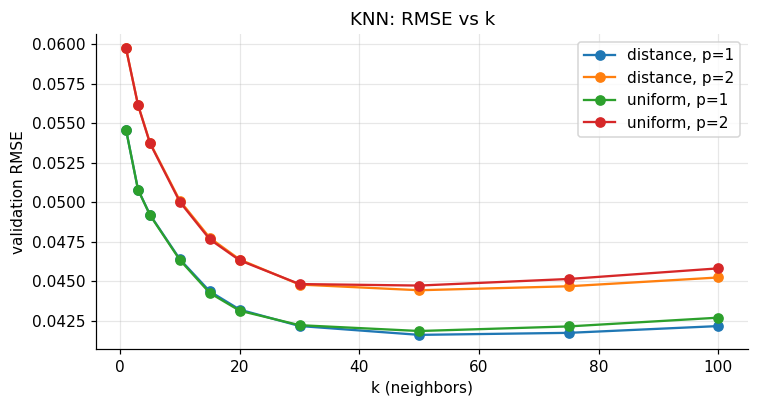

In [19]:
knn_search = tune("KNN regression", make_pipe(KNeighborsRegressor()),
                  {"model__n_neighbors": [1, 3, 5, 10, 15, 20, 30, 50, 75, 100],
                   "model__weights": ["uniform", "distance"], "model__p": [1, 2]})

r = pd.DataFrame(knn_search.cv_results_)
plt.figure(figsize=(7, 3.8))
for (w, p), g in r.groupby(["param_model__weights", "param_model__p"]):
    plt.plot(g.param_model__n_neighbors, -g.mean_test_rmse, "o-", label=f"{w}, p={p}")
plt.xlabel("k (neighbors)"); plt.ylabel("validation RMSE"); plt.title("KNN: RMSE vs k")
plt.legend(); plt.tight_layout(); plt.show()

**Observations:**
* Error falls steeply as *k* grows from 1 and reaches its minimum at **k = 50**, using Manhattan distance (p = 1) and distance weighting. CV RMSE is **0.042**.
* Manhattan distance beats Euclidean at every *k*. With many standardized features, it is less dominated by a single extreme feature.
* The best *k* is large because of the grouped split. A validation country-year cannot use the same country's other years as neighbors, so KNN has to average over many *similar* countries.
* Training RMSE is 0 because, with distance weighting, every training point is its own nearest neighbor.

### 5.6 Decision tree regression
We tune `max_depth` and `min_samples_leaf` to control overfitting.

best params: {'max_depth': 20, 'min_samples_leaf': 10}
Decision tree                  CV RMSE = 0.0547 ± 0.0045 | MAE = 0.0429 | R² = 0.884 | train RMSE = 0.0139


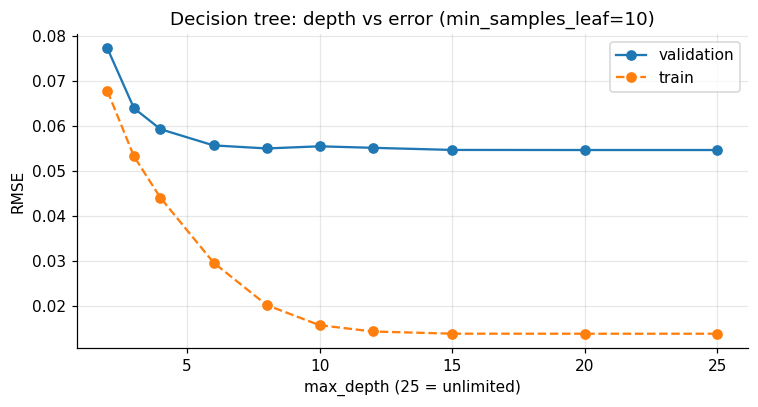

In [20]:
tree_search = tune("Decision tree", make_pipe(DecisionTreeRegressor(random_state=RANDOM_STATE)),
                   {"model__max_depth": [2, 3, 4, 6, 8, 10, 12, 15, 20, None],
                    "model__min_samples_leaf": [1, 5, 10, 20, 50]})

r = pd.DataFrame(tree_search.cv_results_)
best_leaf = tree_search.best_params_["model__min_samples_leaf"]
g = r[r.param_model__min_samples_leaf == best_leaf].copy()
g["depth"] = g.param_model__max_depth.fillna(25).astype(int)
plt.figure(figsize=(7, 3.8))
plt.plot(g.depth, -g.mean_test_rmse, "o-", label="validation")
plt.plot(g.depth, -g.mean_train_rmse, "o--", label="train")
plt.xlabel("max_depth (25 = unlimited)"); plt.ylabel("RMSE")
plt.title(f"Decision tree: depth vs error (min_samples_leaf={best_leaf})"); plt.legend(); plt.tight_layout(); plt.show()

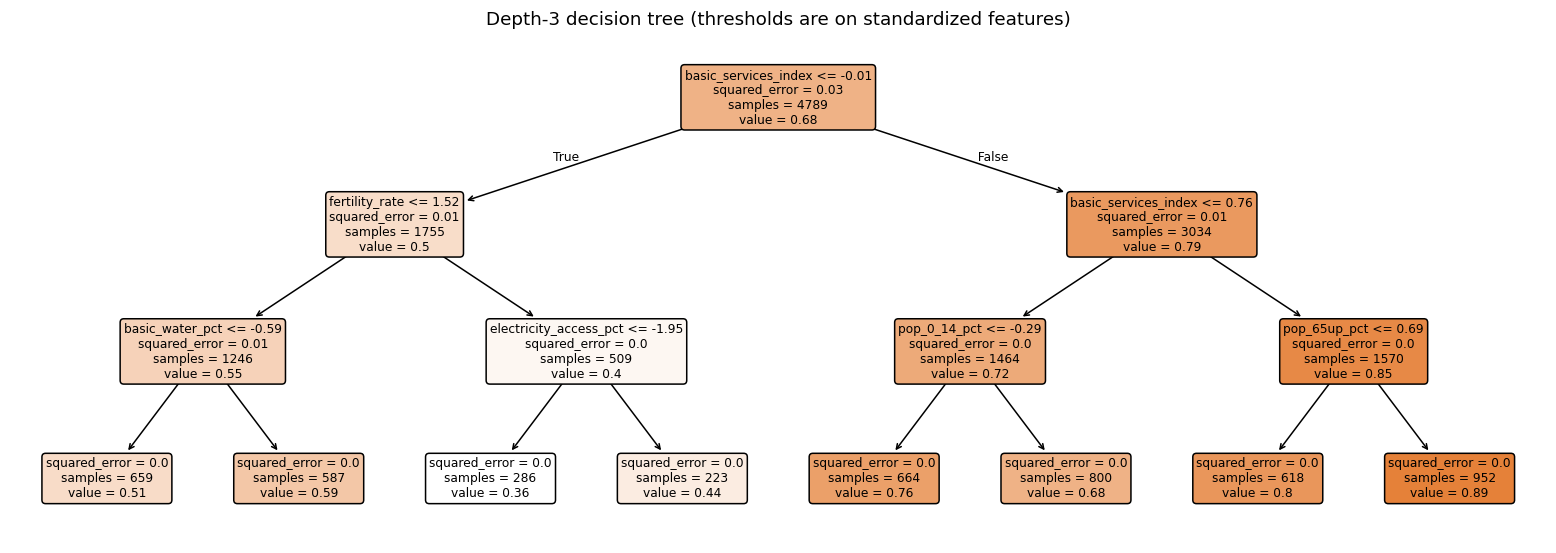

In [21]:
# A shallow (depth-3) tree, fit only to show which splits matter most
shallow = make_pipe(DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE)).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(18, 6))
plot_tree(shallow.named_steps["model"],
          feature_names=[n.split("__")[1] for n in shallow.named_steps["pre"].get_feature_names_out()],
          filled=True, rounded=True, fontsize=8, precision=2, ax=ax)
ax.set_title("Depth-3 decision tree (thresholds are on standardized features)")
plt.show()

**Observations:**
* **Overfitting:** training error keeps falling as depth increases, but validation error levels off at about **0.055** after depth 6–8. The best tree (min_samples_leaf = 10) has the largest train–validation gap of all six models.
* A single tree predicts in **steps**, one constant value per leaf, which is a poor fit for a smooth target like HDI. It is the weakest of the tuned models.
* **Readability:** the depth-3 tree shows the model's logic most clearly. It splits first on `basic_services_index`, then on fertility and age structure: low services with high fertility lead to the lowest HDI (~0.36), and high services with an older population lead to the highest (~0.89).

### 5.7 Support vector machine (SVR)
Support vector regression with an RBF kernel models smooth non-linear relationships. Errors smaller than `epsilon` are ignored. We tune:
* `C`: how much the model is penalized for errors; lower means a smoother fit,
* `gamma`: how far each training point's influence reaches,
* `epsilon`.

best params: {'C': 0.03, 'epsilon': 0.02, 'gamma': 0.003}
SVM (SVR, RBF kernel)          CV RMSE = 0.0401 ± 0.0041 | MAE = 0.0316 | R² = 0.939 | train RMSE = 0.0334


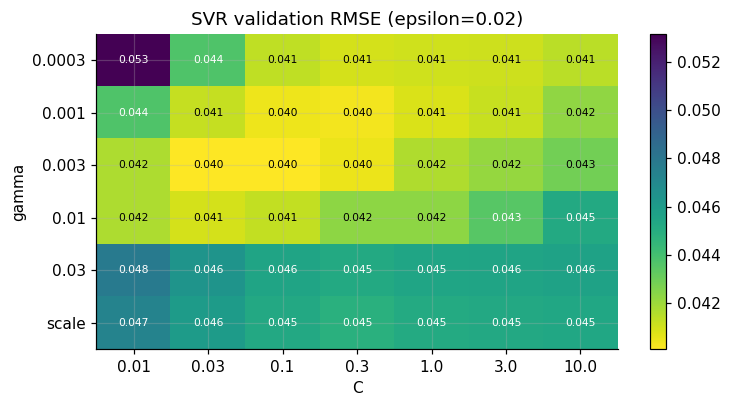

In [22]:
svr_search = tune("SVM (SVR, RBF kernel)", make_pipe(SVR(kernel="rbf")),
                  {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
                   "model__gamma": ["scale", 0.0003, 0.001, 0.003, 0.01, 0.03],
                   "model__epsilon": [0.005, 0.01, 0.02]})

r = pd.DataFrame(svr_search.cv_results_)
best_eps = svr_search.best_params_["model__epsilon"]
heat = (-r[r.param_model__epsilon == best_eps]
        .pivot_table(index="param_model__gamma", columns="param_model__C", values="mean_test_rmse", aggfunc="first"))
heat.index = heat.index.astype(str)
fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(heat.values, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index)
for (i, j), v in np.ndenumerate(heat.values):
    ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7, color="white" if v > heat.values.mean() else "black")
ax.set(xlabel="C", ylabel="gamma", title=f"SVR validation RMSE (epsilon={best_eps})")
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

**Observations:**
* The best SVR is **heavily smoothed**: C = 0.03, gamma = 0.003, epsilon = 0.02. Its CV RMSE is **0.040**, the best of all six models.
* **Trade-off between C and gamma:** the heatmap has a broad valley around RMSE 0.040–0.041 along the diagonal. A small C with a moderate gamma works about as well as a larger C with a smaller gamma. A large gamma (0.03 or `scale`) makes the fit too wiggly, raising RMSE to about 0.045–0.048.
* **Training vs CV:** training RMSE (0.033) is close to CV RMSE (0.040). Of the strong models, SVR overfits the least.

### 5.8 Neural network (multi-layer perceptron)
A feed-forward neural network with ReLU activations, trained with Adam. **Early stopping** halts training once the score on an internal validation split stops improving. We tune:
* the architecture (layers and units),
* the L2 penalty `alpha`,
* the learning rate,
* the batch size.

The search is randomized because there are many combinations.

best params: {'learning_rate_init': 0.001, 'hidden_layer_sizes': (16,), 'batch_size': 64, 'alpha': 0.1}
Neural network (MLP)           CV RMSE = 0.0409 ± 0.0039 | MAE = 0.0320 | R² = 0.937 | train RMSE = 0.0246


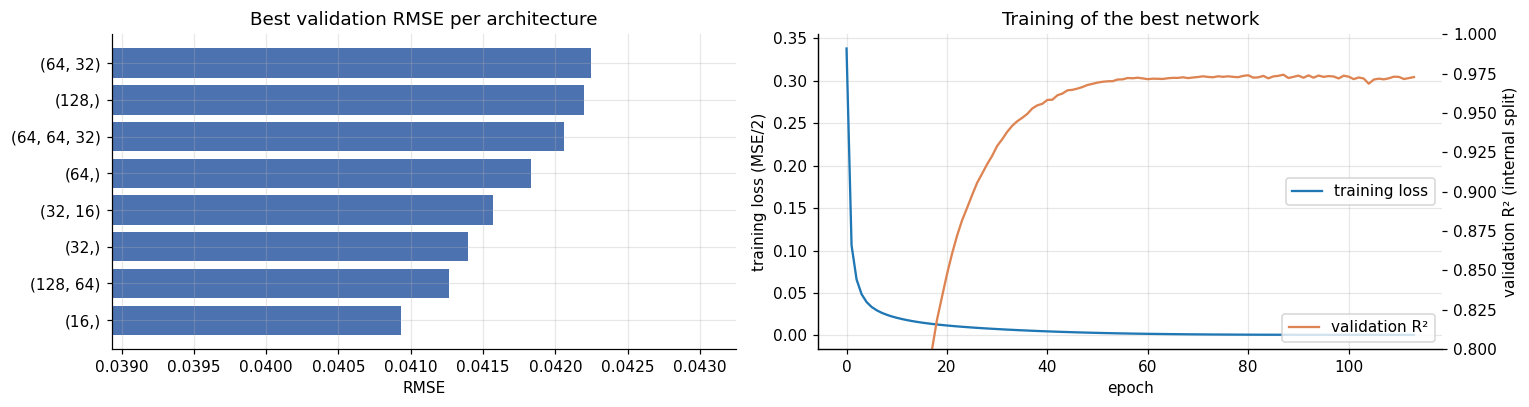

Best network stopped after 114 epochs


In [23]:
mlp_search = tune("Neural network (MLP)",
                  make_pipe(MLPRegressor(early_stopping=True, max_iter=2000, n_iter_no_change=25,
                                         random_state=RANDOM_STATE)),
                  {"model__hidden_layer_sizes": [(16,), (32,), (64,), (128,), (32, 16), (64, 32), (128, 64), (64, 64, 32)],
                   "model__alpha": [1e-4, 1e-3, 1e-2, 0.1, 1.0],
                   "model__learning_rate_init": [3e-4, 1e-3, 3e-3, 1e-2],
                   "model__batch_size": [32, 64, 128]},
                  n_iter=40)

r = pd.DataFrame(mlp_search.cv_results_)
r["arch"] = r.param_model__hidden_layer_sizes.astype(str)
best_mlp = fitted["Neural network (MLP)"].named_steps["model"]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
arch = r.groupby("arch").mean_test_rmse.max().pipe(lambda s: -s).sort_values()
axes[0].barh(arch.index, arch.values, color="#4C72B0")
axes[0].set(title="Best validation RMSE per architecture", xlabel="RMSE",
            xlim=(arch.min() - 0.002, arch.max() + 0.001))
axes[1].plot(best_mlp.loss_curve_, label="training loss")
ax2 = axes[1].twinx(); ax2.plot(best_mlp.validation_scores_, color="#DD8452", label="validation R²")
axes[1].set(title="Training of the best network", xlabel="epoch", ylabel="training loss (MSE/2)")
ax2.set_ylabel("validation R² (internal split)"); ax2.set_ylim(0.8, 1.0); ax2.grid(False)
axes[1].legend(loc="center right"); ax2.legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"Best network stopped after {best_mlp.n_iter_} epochs")

**Observations:**
* The best network is the **smallest one tried**: one hidden layer of 16 units, with a fairly strong L2 penalty (alpha = 0.1). Its CV RMSE is **0.041**.
* All architectures score within about 0.001 of each other. Bigger or deeper networks don't help with ~4,800 training rows; regularization matters more than size.
* **Early stopping** ended training after 114 epochs. Validation R² levels off early, while training loss keeps falling slowly.

### 5.9 Comparison (cross-validation)

,cv_rmse,cv_rmse_std,cv_mae,cv_r2,train_rmse
"SVM (SVR, RBF kernel)",0.0401,0.0041,0.0316,0.939,0.0334
Neural network (MLP),0.0409,0.0039,0.0320,0.937,0.0246
KNN regression,0.0416,0.0027,0.0313,0.932,0.0000
Multiple linear regression,0.0445,0.0051,0.0353,0.923,0.0349
Polynomial regression,0.0503,0.0038,0.0400,0.904,0.0467
Decision tree,0.0547,0.0045,0.0429,0.884,0.0139
Simple linear regression,0.0727,0.0059,0.0596,0.792,0.0721


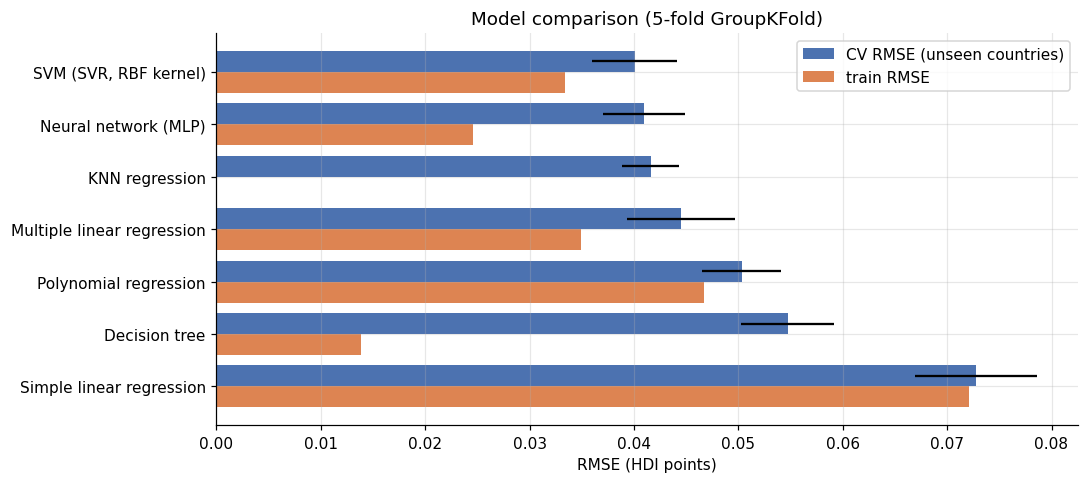

In [24]:
cv_table = pd.DataFrame(results).T.sort_values("cv_rmse")
display(cv_table.style.format({"cv_rmse": "{:.4f}", "cv_rmse_std": "{:.4f}", "cv_mae": "{:.4f}",
                               "cv_r2": "{:.3f}", "train_rmse": "{:.4f}"})
        .background_gradient(subset=["cv_rmse"], cmap="RdYlGn_r"))

fig, ax = plt.subplots(figsize=(10, 4.5))
yy = np.arange(len(cv_table))
ax.barh(yy - 0.2, cv_table.cv_rmse, 0.4, xerr=cv_table.cv_rmse_std, label="CV RMSE (unseen countries)", color="#4C72B0")
ax.barh(yy + 0.2, cv_table.train_rmse, 0.4, label="train RMSE", color="#DD8452")
ax.set_yticks(yy, cv_table.index); ax.invert_yaxis()
ax.set(xlabel="RMSE (HDI points)", title="Model comparison (5-fold GroupKFold)")
ax.legend(); plt.tight_layout(); plt.show()

**Observations:**
* **SVM (0.040), neural network (0.041) and KNN (0.042)** perform best. They are within one fold standard deviation (~0.004) of each other, so cross-validation can't clearly separate them.
* These three non-linear models beat **multiple linear regression (0.045)** by roughly 7–10%, which confirms the non-linear relationships seen in 3.4.
* **Polynomial regression (0.050)** and the **decision tree (0.055)** are the weakest. The polynomial model is limited to 3 features to avoid overfitting, and the tree's step-shaped predictions and high variance hurt it.
* All six models are far better than the one-feature reference (0.073).
* **Train vs CV error:** the tree and KNN fit the training data almost perfectly but generalize no better than SVR. SVR and linear regression have the smallest gaps.
* Caveat: each model's settings were chosen on these same folds, so CV scores are slightly optimistic. The test set in Section 6 is the unbiased check.

## 6. Results on the Test Set

### 6.1 Held-out test countries
Each tuned model was refit on all training countries. We now score each one **once** on the 39 held-out test countries.

In [25]:
rows = []
for name, est in fitted.items():
    pred = est.predict(X_test)
    rows.append({"model": name, "test_rmse": root_mean_squared_error(y_test, pred),
                 "test_mae": mean_absolute_error(y_test, pred), "test_r2": r2_score(y_test, pred),
                 "cv_rmse": results[name]["cv_rmse"]})
test_table = pd.DataFrame(rows).set_index("model").sort_values("test_rmse")
display(test_table.style.format("{:.4f}").background_gradient(subset=["test_rmse"], cmap="RdYlGn_r"))

# The final model is chosen by CV score, so the test set stays an unbiased check.
best_name = cv_table.index[0]
best_model = fitted[best_name]
print(f"Best model by CV: {best_name} -> test RMSE {test_table.loc[best_name, 'test_rmse']:.4f}, "
      f"test R² {test_table.loc[best_name, 'test_r2']:.3f}")

,test_rmse,test_mae,test_r2,cv_rmse
model,,,,
Neural network (MLP),0.0489,0.0337,0.9023,0.0409
"SVM (SVR, RBF kernel)",0.0527,0.0353,0.8865,0.0401
KNN regression,0.0562,0.0388,0.8712,0.0416
Multiple linear regression,0.0569,0.0396,0.8678,0.0445
Polynomial regression,0.0584,0.0449,0.8608,0.0503
Decision tree,0.0610,0.0451,0.8483,0.0547
Simple linear regression,0.0706,0.0550,0.7966,0.0727


Best model by CV: SVM (SVR, RBF kernel) -> test RMSE 0.0527, test R² 0.887


**Observations:**
* On the 39 held-out countries, the **neural network scores best (RMSE 0.049, R² 0.90)**, followed by SVM (0.053), KNN (0.056), linear regression (0.057), polynomial regression (0.058) and the decision tree (0.061).
* The top three swap places compared with CV because their differences are small. We still report **SVM as our final model**, because it was chosen by CV. Switching to the neural network after seeing test scores would make the test set no longer an unbiased estimate.
* Every model's test RMSE is higher than its CV RMSE. Test MAE (~0.034–0.035 for the top models) is close to CV MAE (~0.032), however, so the gap comes from a **few large errors**, which RMSE weights heavily (6.3).

### 6.2 Predicted vs actual

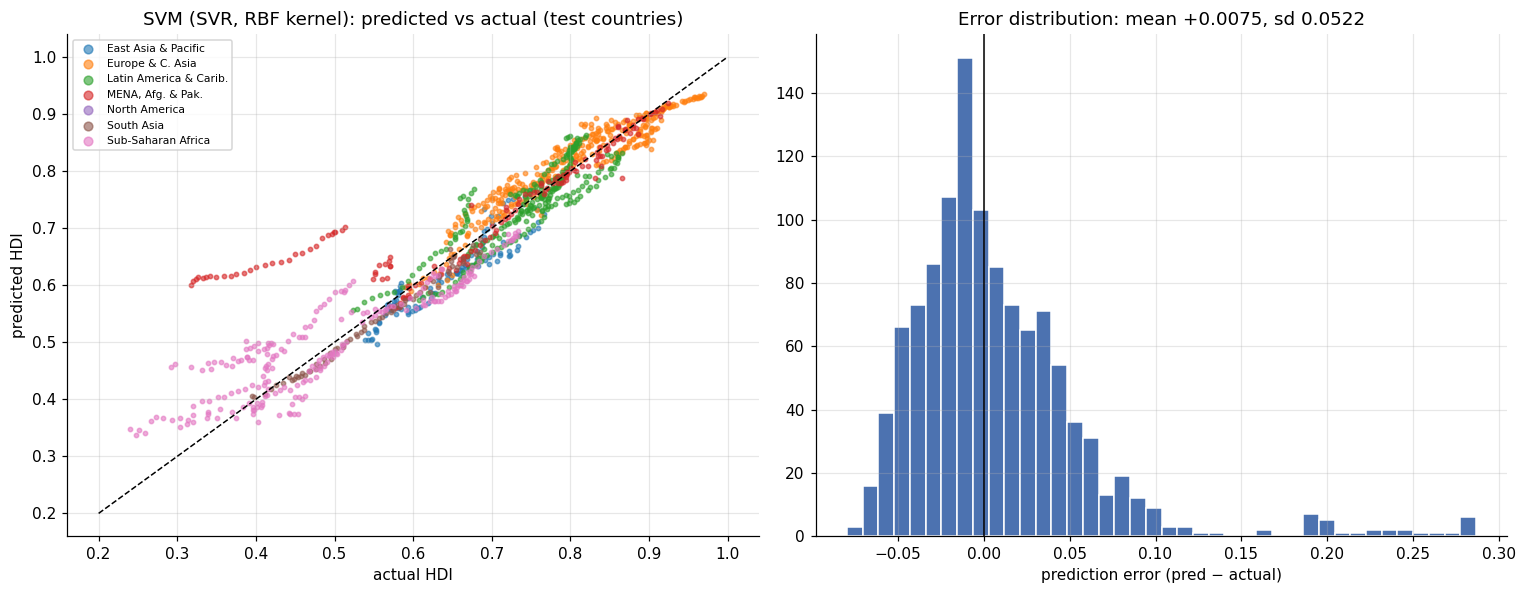

In [26]:
test_df = data.iloc[test_idx][["iso3", "country", "year", "region", "hdi"]].copy()
test_df["pred"] = best_model.predict(X_test)
test_df["error"] = test_df.pred - test_df.hdi
test_df["abs_error"] = test_df.error.abs()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for r in regions:
    m = test_df.region == r
    axes[0].scatter(test_df.loc[m, "hdi"], test_df.loc[m, "pred"], s=8, alpha=0.6, color=REGION_COLORS[r], label=r)
axes[0].plot([0.2, 1], [0.2, 1], "k--", lw=1)
axes[0].set(xlabel="actual HDI", ylabel="predicted HDI", title=f"{best_name}: predicted vs actual (test countries)")
axes[0].legend(fontsize=7, markerscale=2)
axes[1].hist(test_df.error, bins=40, color="#4C72B0", edgecolor="white")
axes[1].axvline(0, color="k", lw=1)
axes[1].set(xlabel="prediction error (pred − actual)",
            title=f"Error distribution: mean {test_df.error.mean():+.4f}, sd {test_df.error.std():.4f}")
plt.tight_layout(); plt.show()

### 6.3 Error analysis

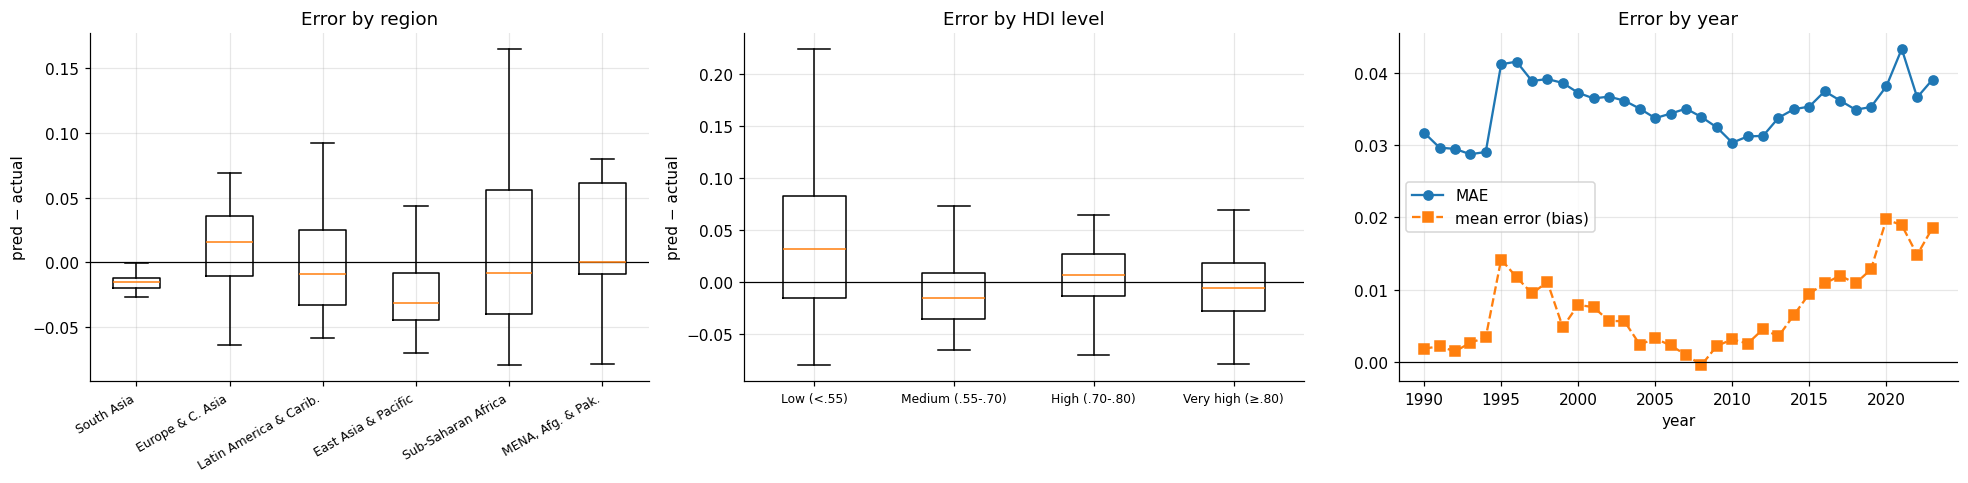

MAE / bias by HDI band:
                      mae    bias
hdi_band                        
Low (<.55)        0.0675  0.0490
Medium (.55-.70)  0.0308 -0.0086
High (.70-.80)    0.0259  0.0040
Very high (≥.80)  0.0244 -0.0040

MAE by region:
 region
South Asia                0.0157
Europe & C. Asia          0.0271
Latin America & Carib.    0.0293
East Asia & Pacific       0.0316
Sub-Saharan Africa        0.0476
MENA, Afg. & Pak.         0.0568


In [27]:
test_df["hdi_band"] = pd.cut(test_df.hdi, [0, 0.55, 0.70, 0.80, 1],
                             labels=["Low (<.55)", "Medium (.55-.70)", "High (.70-.80)", "Very high (≥.80)"])
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
reg_order = test_df.groupby("region").abs_error.mean().sort_values().index
axes[0].boxplot([test_df.loc[test_df.region == r, "error"] for r in reg_order], showfliers=False)
axes[0].set_xticks(range(1, len(reg_order) + 1), reg_order, rotation=30, ha="right", fontsize=8)
axes[0].axhline(0, color="k", lw=0.8); axes[0].set(title="Error by region", ylabel="pred − actual")
bands = test_df.hdi_band.cat.categories
axes[1].boxplot([test_df.loc[test_df.hdi_band == b, "error"] for b in bands], showfliers=False)
axes[1].set_xticks(range(1, len(bands) + 1), bands, fontsize=8)
axes[1].axhline(0, color="k", lw=0.8); axes[1].set(title="Error by HDI level", ylabel="pred − actual")
yr = test_df.groupby("year").agg(mae=("abs_error", "mean"), bias=("error", "mean"))
axes[2].plot(yr.index, yr.mae, "o-", label="MAE"); axes[2].plot(yr.index, yr.bias, "s--", label="mean error (bias)")
axes[2].axhline(0, color="k", lw=0.8); axes[2].set(title="Error by year", xlabel="year"); axes[2].legend()
plt.tight_layout(); plt.show()

print("MAE / bias by HDI band:\n", test_df.groupby("hdi_band", observed=True)
      .agg(mae=("abs_error", "mean"), bias=("error", "mean")).round(4).to_string())
print("\nMAE by region:\n", test_df.groupby("region").abs_error.mean().sort_values().round(4).to_string())

Hardest test countries:


,region,mae,bias,mean_hdi
country,,,,
Djibouti,"MENA, Afg. & Pak.",0.230,0.230,0.413
South Sudan,Sub-Saharan Africa,0.103,0.103,0.372
Gambia,Sub-Saharan Africa,0.079,0.079,0.437
Mali,Sub-Saharan Africa,0.057,0.057,0.358
Bosnia and Herzegovina,Europe & C. Asia,0.055,0.055,0.740
Marshall Islands,East Asia & Pacific,0.052,-0.052,0.702


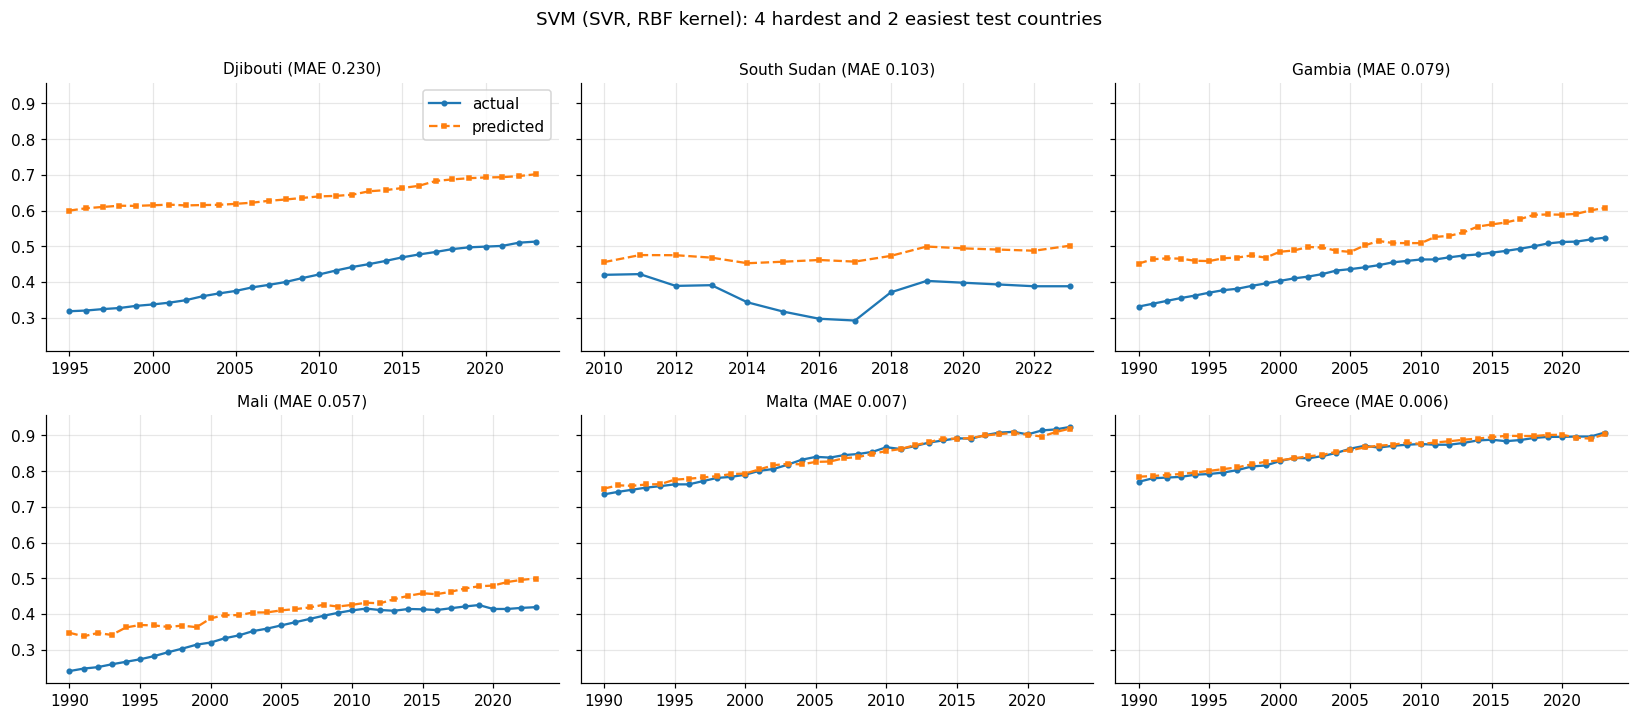

In [28]:
per_country = (test_df.groupby("country").agg(region=("region", "first"), mae=("abs_error", "mean"),
                                              bias=("error", "mean"), mean_hdi=("hdi", "mean"))
               .sort_values("mae", ascending=False))
print("Hardest test countries:"); display(per_country.head(6).round(3))

show = list(per_country.index[:4]) + list(per_country.index[-2:])
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharey=True)
for ax, c in zip(axes.flat, show):
    d = test_df[test_df.country == c]
    ax.plot(d.year, d.hdi, "o-", ms=3, label="actual"); ax.plot(d.year, d.pred, "s--", ms=3, label="predicted")
    ax.set_title(f"{c} (MAE {per_country.loc[c, 'mae']:.3f})", fontsize=10)
axes[0, 0].legend(); plt.suptitle(f"{best_name}: 4 hardest and 2 easiest test countries", y=1.0)
plt.tight_layout(); plt.show()

**Observations (SVM):**
* **The poorest countries are hardest.** For HDI < 0.55, MAE is 0.068 and the model **over-predicts** them by +0.049 on average. For very high HDI, MAE is 0.024.
* **By region:** South Asia is easiest (MAE 0.016). MENA/Afghanistan/Pakistan (0.057) and Sub-Saharan Africa (0.048) are hardest.
* **Over time:** errors are stable at about 0.03–0.04. The model **over-predicts more after 2015**, and most of all in 2020–2021, when actual HDI fell during COVID-19 but the slow-moving structural indicators did not.
* **Djibouti (MAE 0.23)** is the largest error. On our features it looks like a middle-income country: 72% urban, ~1% agricultural employment, services are 77% of GDP, and fertility is 2.7. Its HDI is low mainly because of **schooling and life expectancy**, exactly the HDI inputs we excluded.
* **South Sudan (MAE 0.10)** is missing several indicators entirely, such as internet use and services share. These are filled with the training median, which describes a much more developed country.

### 6.4 Feature importance
**Permutation importance** measures how much the best model's test RMSE increases when one feature's values are randomly shuffled.

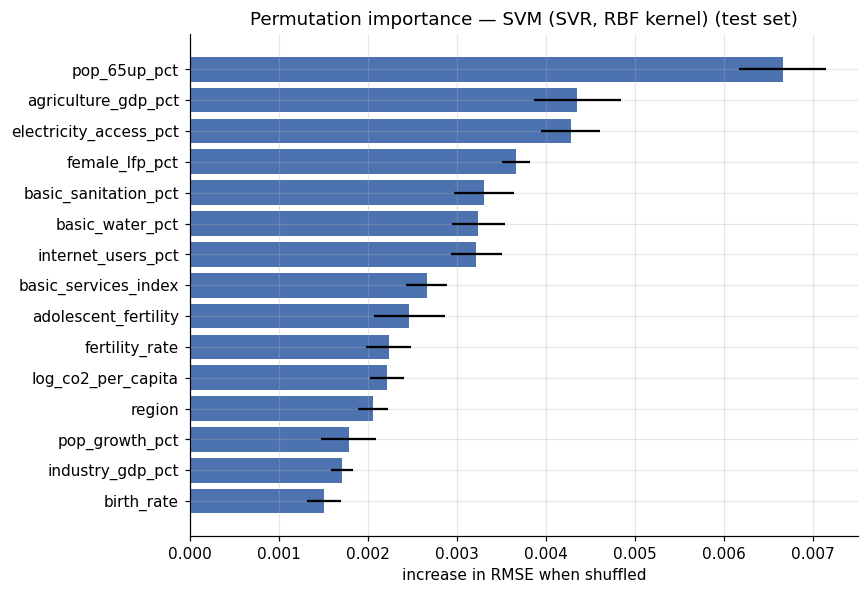

pop_65up_pct              0.0067
agriculture_gdp_pct       0.0044
electricity_access_pct    0.0043
female_lfp_pct            0.0037
basic_sanitation_pct      0.0033
basic_water_pct           0.0032
internet_users_pct        0.0032
basic_services_index      0.0027


In [29]:
perm = permutation_importance(best_model, X_test, y_test, scoring="neg_root_mean_squared_error",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp_std = pd.Series(perm.importances_std, index=X_test.columns)
top = imp.head(15)[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top.index, top.values, xerr=imp_std[top.index], color="#4C72B0")
plt.title(f"Permutation importance — {best_name} (test set)"); plt.xlabel("increase in RMSE when shuffled")
plt.tight_layout(); plt.show()
print(imp.head(8).round(4).to_string())

**Observations:**
* For the SVM, the most important features are the **share of population over 65**, the **agricultural share of GDP**, and **access to electricity, sanitation and water**, followed by **female labor force participation** and **internet use**.
* The importance is **spread across many features**. Shuffling any single feature raises RMSE by at most ~0.007, because each feature has highly correlated partners that carry similar information (3.5).
* `basic_services_index` ranks lower here than in the depth-3 tree. Its four components are also in the model, so shuffling the index alone removes little information.

## 7. Summary

| | Result |
|---|---|
| **Task** | Predict HDI for unseen countries from 26 World Bank indicators that are **not** HDI inputs (life expectancy, schooling, GNI and their stand-ins are removed) |
| **Data** | 5,940 country-years, 193 countries, 1990–2023; split 80/20 **by country** |
| **Best by CV** | SVM (RBF): CV RMSE 0.040 → **test RMSE 0.053, R² 0.89** |
| **Best on test** | Neural network: test RMSE 0.049, R² 0.90 (CV RMSE 0.041) |
| **Other models (test RMSE)** | KNN 0.056 · linear 0.057 · polynomial 0.058 · decision tree 0.061 |
| **Hardest cases** | the poorest countries (over-predicted), MENA and Sub-Saharan Africa; Djibouti and South Sudan |

**Key takeaways**
1. HDI can be predicted well (R² ≈ 0.89–0.90 on unseen countries) **without using any of its formula inputs**. The best signals are access to basic services, age structure and the size of the agricultural sector.
2. **The smooth non-linear models (SVM, neural network, KNN) beat linear regression** by ~7–10%. Polynomial regression and decision trees overfit easily and needed strong limits.
3. **The best-tuned models were the most regularized ones:** small C in the SVM, a small network with a strong L2 penalty, large *k* in KNN, and few features in polynomial regression.
4. **Limitations:** countries whose low HDI comes from health and education outcomes not reflected in structural indicators (Djibouti); countries missing entire indicators (South Sudan); and recent years (2020–2023), when HDI dipped but the indicators did not.